# Exploratory Data Analysis

## Main findings and summary

- **Training data:** The analysis uses 21,900 prompts from the existing training partition, covering 85 task categories and 11 models. The final membership checks confirm that the analyzed prompt IDs exactly match the saved training IDs.

- **Task imbalance:** HellaSwag contributes 5,997 prompts and grade-school-math contributes 4,492. Together, they account for 47.89% of training prompts, giving these tasks substantial influence over prompt-weighted averages.

- **Score distributions:** There are 13 distinct recorded score values. The five levels 0, 0.25, 0.5, 0.75, and 1 account for approximately 99.86% of prompt–model scores. Fractional scores occur in six task categories, with grade-school-math contributing most of them. Mean recorded score should therefore be interpreted as average benchmark quality, rather than automatically as binary accuracy.

- **Model-levels:** GPT-4 has the highest mean recorded score, approximately 0.7800, and the highest average historical cost, approximately $3.298 per 1,000 responses. Mistral 7B has the lowest average historical cost, approximately $0.0456 per 1,000 responses, with a mean score of approximately 0.3072.

- **Multiple cost peaks:** Costs are positive and right-skewed. The pooled log-cost distributions have several peaks, which largely collapse after subtracting each task’s mean log cost.

- **Prompt length:** Prompt length in characters has a strong positive association with cost: overall Spearman correlations range from 0.830 to 0.892 across models. Positive associations persist within the three largest tasks. 

- **Model complementarity:** Other models sometimes outperform GPT-4 on individual prompts despite having lower overall mean scores. Claude-instant scores higher than GPT-4 on 8.15% of training prompts. Yi has the largest average positive score improvement over GPT-4, approximately 0.0534 score units averaged across all training prompts, with non-improvements counted as zero.

- **Perfect-information savings:** Selecting the cheapest model whose recorded score matches or exceeds GPT-4’s on each prompt reduces average historical cost from approximately $3.298 to $0.207 per 1,000 responses—a 93.71% saving. Under equal task weighting, the saving is 87.94%. These are hindsight benchmarks requiring knowledge of every candidate’s outcome. 

- **Repeated prompts:** The training partition contains 12 pairs of identical extracted prompt texts, involving 24 rows. Four pairs differ in at least one model score, and nine differ in at least one model cost.

## Scope and limitations

These findings describe the existing training partition before embedding.

# Code

## Load training data set

In [58]:
from pathlib import Path
import pandas as pd

DATA_LOCATION = Path(
    "1_data_preparation/data/raw/routerbench_0shot.pkl"
)

PROJECT_DIR = None

for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / DATA_LOCATION).is_file():
        PROJECT_DIR = folder
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Dataset not found. Run this notebook from within the project "
        "and check that 1_data_preparation/data/raw/routerbench_0shot.pkl exists."
    )

RAW_PATH = PROJECT_DIR / DATA_LOCATION

df = pd.read_pickle(RAW_PATH)

split_dir = RAW_PATH.parent.parent / "processed" / "char_tfidf_50k"
train_questions = pd.read_pickle(split_dir / "train_questions.pkl")
train_ids = train_questions["sample_id"]

# Keep only raw-data rows whose IDs belong to the saved training split.
df = df.loc[df["sample_id"].isin(train_ids)].copy()

# Stop if IDs are missing, repeated, or do not match the raw dataset.
assert len(train_ids) > 0, "The saved training split is empty."
assert train_ids.notna().all() and train_ids.is_unique, "Invalid training IDs."
assert df["sample_id"].is_unique, "Repeated training IDs in the raw dataset."
assert set(df["sample_id"]) == set(train_ids), "Some training IDs are missing."

print(f"Training partition loaded: {len(df):,} prompts.")

Training partition loaded: 21,900 prompts.


## Dataset features

In [59]:
df.shape        # Return (number of rows, number of columns).

(21900, 37)

In [60]:
df.columns      # Show the column names.
# sample_id, prompt, eval_name: Prompt identifier, prompt text, and task category 
# Columns named after 11 models  11 - Each model’s recorded score for that prompt
# Columns ending in model_response - Each model’s generated answer |
# Columns ending in total_cost - response cost for each model 
# oracle_model_to_route_to -  A stored hindsight model-selection label 

Index(['sample_id', 'prompt', 'eval_name', 'WizardLM/WizardLM-13B-V1.2',
       'claude-instant-v1', 'claude-v1', 'claude-v2', 'gpt-3.5-turbo-1106',
       'gpt-4-1106-preview', 'meta/code-llama-instruct-34b-chat',
       'meta/llama-2-70b-chat', 'mistralai/mistral-7b-chat',
       'mistralai/mixtral-8x7b-chat', 'zero-one-ai/Yi-34B-Chat',
       'gpt-3.5-turbo-1106|model_response', 'claude-instant-v1|model_response',
       'claude-v1|model_response', 'claude-v2|model_response',
       'gpt-4-1106-preview|model_response',
       'meta/llama-2-70b-chat|model_response',
       'mistralai/mixtral-8x7b-chat|model_response',
       'zero-one-ai/Yi-34B-Chat|model_response',
       'WizardLM/WizardLM-13B-V1.2|model_response',
       'meta/code-llama-instruct-34b-chat|model_response',
       'mistralai/mistral-7b-chat|model_response',
       'gpt-3.5-turbo-1106|total_cost', 'claude-instant-v1|total_cost',
       'claude-v1|total_cost', 'claude-v2|total_cost',
       'gpt-4-1106-preview|total_c

In [61]:
df.head()       # Show the first five rows.

,sample_id,prompt,eval_name,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,...,claude-v1|total_cost,claude-v2|total_cost,gpt-4-1106-preview|total_cost,meta/llama-2-70b-chat|total_cost,mistralai/mixtral-8x7b-chat|total_cost,zero-one-ai/Yi-34B-Chat|total_cost,WizardLM/WizardLM-13B-V1.2|total_cost,meta/code-llama-instruct-34b-chat|total_cost,mistralai/mistral-7b-chat|total_cost,oracle_model_to_route_to
0,Chinese_character_riddles.dev.0,['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...,Chinese_character_riddles,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.004904,0.006488,0.00973,0.000266,0.000166,0.000250,0.000103,0.000236,0.000062,no_model_correct
3,Chinese_character_riddles.dev.11,['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...,Chinese_character_riddles,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.003088,0.004960,0.00908,0.000287,0.000117,0.000318,0.000104,0.000315,0.000045,zero-one-ai/Yi-34B-Chat
4,Chinese_character_riddles.dev.12,['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...,Chinese_character_riddles,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.002272,0.004912,0.01322,0.000254,0.000097,0.000210,0.000112,0.000190,0.000039,no_model_correct
5,Chinese_character_riddles.dev.13,['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...,Chinese_character_riddles,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.005640,0.005976,0.00837,0.000247,0.000248,0.000210,0.000076,0.000150,0.000022,no_model_correct
6,Chinese_character_riddles.dev.14,['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...,Chinese_character_riddles,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.002600,0.002336,0.01069,0.000271,0.000099,0.000258,0.000049,0.000294,0.000035,claude-instant-v1


## Types of Tasks

In [62]:
# count number of task categories
task_counts = df["eval_name"].value_counts()
print("Number of task categories:", len(task_counts))
task_counts.head(5)


Number of task categories: 85


eval_name
hellaswag                5997
grade-school-math        4492
mmlu-professional-law     925
arc-challenge             872
winogrande                786
Name: count, dtype: int64

In [63]:
# percentage of task categories
task_summary = pd.DataFrame({
    "prompt_count": task_counts,
    "percentage": 100 * task_counts / len(df)
})

task_summary.head(5).round(2)

,prompt_count,percentage
eval_name,,
hellaswag,5997,27.38
grade-school-math,4492,20.51
mmlu-professional-law,925,4.22
arc-challenge,872,3.98
winogrande,786,3.59


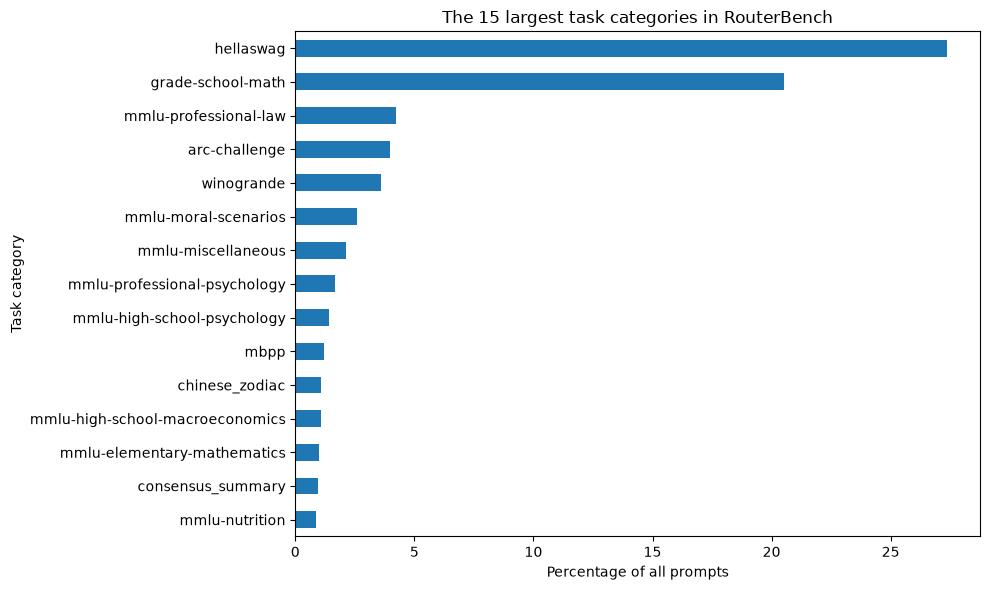

In [64]:
# Vizualize task categories
#%pip install matplotlib
import matplotlib.pyplot as plt

top_tasks = task_summary["percentage"].head(15)

top_tasks.sort_values().plot.barh(figsize=(10, 6))

plt.xlabel("Percentage of all prompts")
plt.ylabel("Task category")
plt.title("The 15 largest task categories in RouterBench")

plt.tight_layout()
plt.show()

## Scores

Summary: Inspect recorded score levels, fractional scores, and model differences using training rows only.

In [65]:
# scores dataframe
score_columns = df.columns[3:14]
scores = df[score_columns].astype("float64")
scores.dtypes

WizardLM/WizardLM-13B-V1.2           float64
claude-instant-v1                    float64
claude-v1                            float64
claude-v2                            float64
gpt-3.5-turbo-1106                   float64
gpt-4-1106-preview                   float64
meta/code-llama-instruct-34b-chat    float64
meta/llama-2-70b-chat                float64
mistralai/mistral-7b-chat            float64
mistralai/mixtral-8x7b-chat          float64
zero-one-ai/Yi-34B-Chat              float64
dtype: object

In [66]:
# describe scores
scores.describe().T

,count,mean,std,min,25%,50%,75%,max
WizardLM/WizardLM-13B-V1.2,21900.0,0.432913,0.451255,0.0,0.00,0.25,1.00,1.0
claude-instant-v1,21900.0,0.596991,0.446973,0.0,0.00,0.75,1.00,1.0
claude-v1,21900.0,0.628566,0.438644,0.0,0.00,0.75,1.00,1.0
claude-v2,21900.0,0.631646,0.436585,0.0,0.00,0.75,1.00,1.0
gpt-3.5-turbo-1106,21900.0,0.618126,0.439535,0.0,0.00,0.75,1.00,1.0
gpt-4-1106-preview,21900.0,0.779986,0.357997,0.0,0.75,1.00,1.00,1.0
meta/code-llama-instruct-34b-chat,21900.0,0.201646,0.345525,0.0,0.00,0.00,0.25,1.0
meta/llama-2-70b-chat,21900.0,0.325543,0.421334,0.0,0.00,0.00,0.75,1.0
mistralai/mistral-7b-chat,21900.0,0.307167,0.414510,0.0,0.00,0.00,0.75,1.0
mistralai/mixtral-8x7b-chat,21900.0,0.545813,0.454212,0.0,0.00,0.75,1.00,1.0


In [67]:
# How many scores are fractional?
score_distribution = pd.DataFrame({
    "Score = 0 (%)": scores.eq(0).mean() * 100,
    "0 < Score < 1 (%)": ((scores > 0) & (scores < 1)).mean() * 100,
    "Score = 1 (%)": scores.eq(1).mean() * 100
})

score_distribution.round(2)

,Score = 0 (%),0 < Score < 1 (%),Score = 1 (%)
WizardLM/WizardLM-13B-V1.2,46.32,21.20,32.48
claude-instant-v1,32.40,21.11,46.49
claude-v1,29.63,21.04,49.32
claude-v2,29.61,21.37,49.02
gpt-3.5-turbo-1106,29.68,21.30,49.02
gpt-4-1106-preview,14.70,21.24,64.06
meta/code-llama-instruct-34b-chat,68.36,21.33,10.32
meta/llama-2-70b-chat,57.33,21.43,21.24
mistralai/mistral-7b-chat,56.92,21.28,21.79
mistralai/mixtral-8x7b-chat,35.33,21.12,43.55


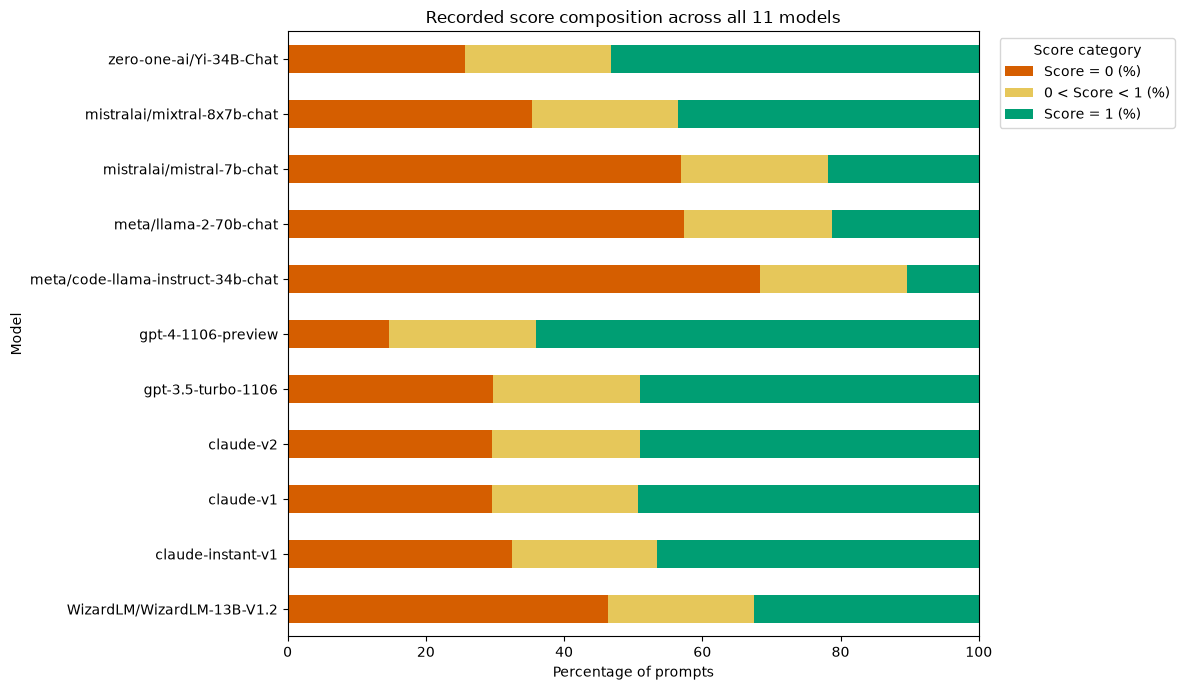

In [68]:
# Vizualize scores across models
score_distribution.plot.barh(
    stacked=True,
    figsize=(12, 7),
    color=["#D55E00", "#E6C75A", "#009E73"]
)

plt.xlabel("Percentage of prompts")
plt.ylabel("Model")
plt.title("Recorded score composition across all 11 models")
plt.xlim(0, 100)

plt.legend(
    title="Score category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [69]:
# What task categories give rise to fractional scores? 
fractional = (scores > 0) & (scores < 1)

fractional_by_task = fractional.groupby(df["eval_name"]).mean() * 100

fractional_by_task.loc[
    fractional_by_task.gt(0).any(axis=1)
].round(2)

,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
eval_name,,,,,,,,,,,
chinese_idioms,69.23,46.15,69.23,23.08,69.23,84.62,61.54,92.31,92.31,92.31,69.23
consensus_summary,62.44,49.30,39.44,82.63,75.12,69.48,85.92,84.04,81.69,88.26,61.97
grade-school-math,99.33,99.55,99.82,99.53,99.40,99.69,98.86,99.40,98.71,97.91,99.44
mtbench,70.37,74.07,51.85,51.85,62.96,18.52,74.07,66.67,81.48,37.04,51.85
mtbench-math,90.00,80.00,70.00,70.00,60.00,50.00,90.00,80.00,90.00,90.00,60.00
mtbench-reference,100.00,100.00,90.91,90.91,63.64,36.36,90.91,100.00,90.91,81.82,100.00


In [70]:
#how does each model’s mean score vary across tasks?
task_scores = scores.groupby(df["eval_name"]).mean()

task_scores.insert(0, "prompt_count", task_counts)

task_scores.sort_values(
    "prompt_count", ascending=False
).head(10).round(3)

,prompt_count,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
eval_name,,,,,,,,,,,,
hellaswag,5997,0.334,0.585,0.569,0.623,0.585,0.837,0.206,0.517,0.254,0.414,0.744
grade-school-math,4492,0.504,0.627,0.649,0.660,0.599,0.658,0.455,0.521,0.410,0.519,0.547
mmlu-professional-law,925,0.344,0.524,0.520,0.497,0.489,0.680,0.002,0.000,0.265,0.509,0.497
arc-challenge,872,0.616,0.802,0.861,0.853,0.836,0.960,0.372,0.737,0.400,0.822,0.861
winogrande,786,0.515,0.609,0.648,0.654,0.581,0.830,0.385,0.490,0.515,0.543,0.649
mmlu-moral-scenarios,567,0.229,0.337,0.354,0.354,0.335,0.753,0.000,0.000,0.000,0.296,0.511
mmlu-miscellaneous,468,0.632,0.761,0.859,0.833,0.874,0.959,0.004,0.175,0.357,0.861,0.870
mmlu-professional-psychology,368,0.448,0.633,0.745,0.677,0.715,0.856,0.008,0.022,0.272,0.704,0.728
mmlu-high-school-psychology,307,0.625,0.798,0.860,0.814,0.834,0.961,0.020,0.036,0.296,0.850,0.870


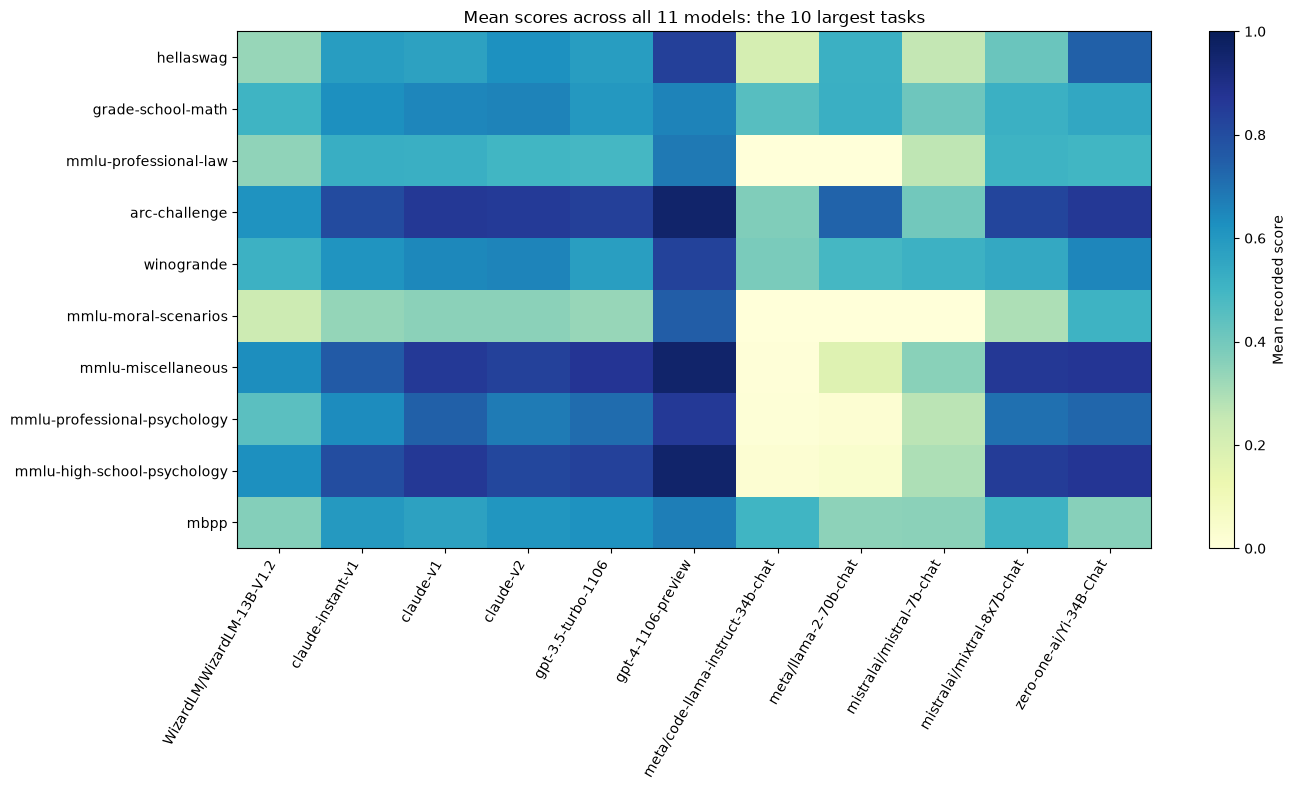

In [71]:
heatmap_data = (
    task_scores
    .sort_values("prompt_count", ascending=False)
    .head(10)
    .drop(columns="prompt_count")
)

plt.figure(figsize=(14, 8))

plt.imshow(
    heatmap_data,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    aspect="auto"
)

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=60,
    ha="right"
)

plt.yticks(
    range(len(heatmap_data)),
    heatmap_data.index
)

plt.colorbar(label="Mean recorded score")
plt.title("Mean scores across all 11 models: the 10 largest tasks")

plt.tight_layout()
plt.show()

In [72]:
# are there distinct scores? 
score_levels = scores.stack().value_counts().sort_index()

print("Number of distinct score values:", len(score_levels))

score_levels

# Five levels dominate: 0, .25, .5, .75, 1.

Number of distinct score values: 13


0.00    93268
0.10       99
0.20       33
0.25    15064
0.30       27
0.40       25
0.50     8075
0.60        3
0.70       29
0.75    27679
0.80       41
0.90       84
1.00    96473
Name: count, dtype: int64

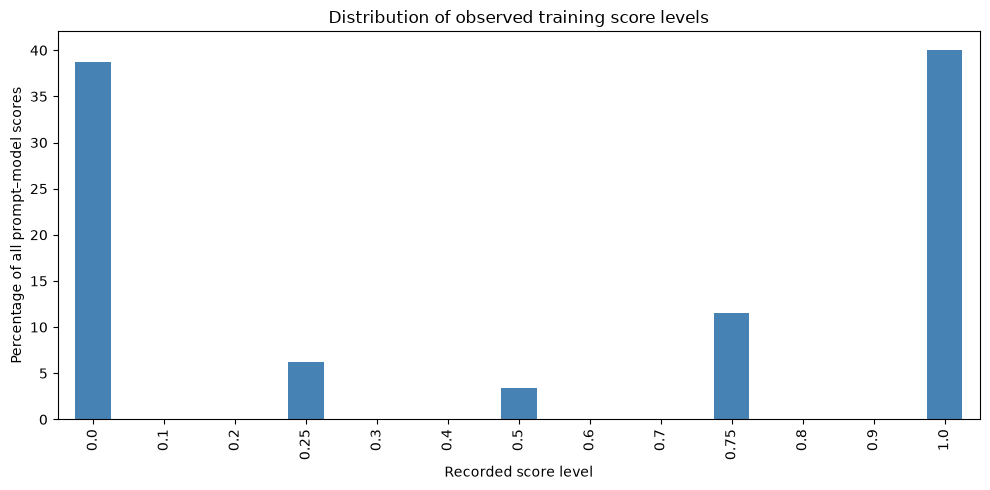

In [73]:
# Vizualize score levels 
score_percentages = 100 * score_levels / score_levels.sum()

score_percentages.plot.bar(
    figsize=(10, 5),
    color="steelblue"
)

plt.xlabel("Recorded score level")
plt.ylabel("Percentage of all prompt–model scores")
plt.title("Distribution of observed training score levels")

plt.tight_layout()
plt.show()

In [74]:
score_details = scores.copy()

score_details["task"] = df["eval_name"]

score_details = score_details.melt(
    id_vars="task",
    var_name="model",
    value_name="score"
)

score_details.head()

,task,model,score
0,Chinese_character_riddles,WizardLM/WizardLM-13B-V1.2,0.0
1,Chinese_character_riddles,WizardLM/WizardLM-13B-V1.2,0.0
2,Chinese_character_riddles,WizardLM/WizardLM-13B-V1.2,0.0
3,Chinese_character_riddles,WizardLM/WizardLM-13B-V1.2,0.0
4,Chinese_character_riddles,WizardLM/WizardLM-13B-V1.2,0.0


In [75]:
# are scores of a task concentrated at a certain level? 
task_level_counts = pd.crosstab(
    score_details["task"],
    score_details["score"]
)

has_fractional = (
    task_level_counts
    .drop(columns=[0.0, 1.0])
    .sum(axis=1) > 0
)

task_level_counts.loc[has_fractional]

score,0.00,0.10,0.20,0.25,0.30,0.40,0.50,0.60,0.70,0.75,0.80,0.90,1.00
task,,,,,,,,,,,,,
chinese_idioms,29,0,0,88,0,0,0,0,0,12,0,0,14
consensus_summary,259,0,0,203,0,0,265,0,0,1194,0,0,422
grade-school-math,191,0,0,14773,0,0,7791,0,0,26473,0,0,184
mtbench,0,4,4,0,10,17,16,2,20,0,31,69,124
mtbench-math,0,56,8,0,10,4,1,0,1,0,2,1,27
mtbench-reference,0,39,21,0,7,4,2,1,8,0,8,14,17


In [76]:
fractional_task_counts = task_level_counts.loc[has_fractional]

task_level_percentages = fractional_task_counts.div(
    fractional_task_counts.sum(axis=1),
    axis=0
) * 100

task_level_percentages.round(2)

score,0.00,0.10,0.20,0.25,0.30,0.40,0.50,0.60,0.70,0.75,0.80,0.90,1.00
task,,,,,,,,,,,,,
chinese_idioms,20.28,0.00,0.00,61.54,0.00,0.00,0.00,0.00,0.00,8.39,0.00,0.00,9.79
consensus_summary,11.05,0.00,0.00,8.66,0.00,0.00,11.31,0.00,0.00,50.96,0.00,0.00,18.01
grade-school-math,0.39,0.00,0.00,29.90,0.00,0.00,15.77,0.00,0.00,53.58,0.00,0.00,0.37
mtbench,0.00,1.35,1.35,0.00,3.37,5.72,5.39,0.67,6.73,0.00,10.44,23.23,41.75
mtbench-math,0.00,50.91,7.27,0.00,9.09,3.64,0.91,0.00,0.91,0.00,1.82,0.91,24.55
mtbench-reference,0.00,32.23,17.36,0.00,5.79,3.31,1.65,0.83,6.61,0.00,6.61,11.57,14.05


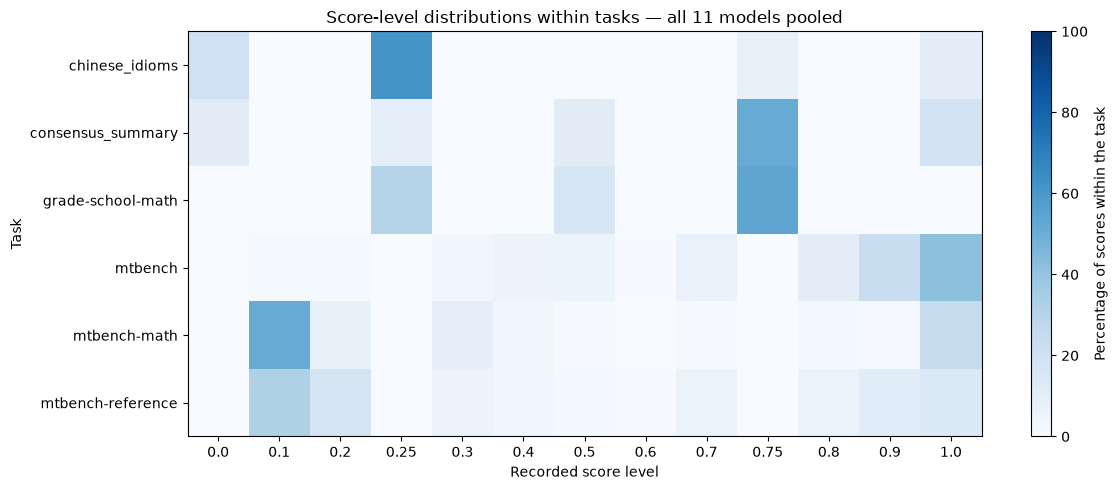

In [77]:
plt.figure(figsize=(12, 5))

plt.imshow(
    task_level_percentages,
    cmap="Blues",
    vmin=0,
    vmax=100,
    aspect="auto"
)

plt.xticks(
    range(len(task_level_percentages.columns)),
    task_level_percentages.columns
)

plt.yticks(
    range(len(task_level_percentages)),
    task_level_percentages.index
)

plt.xlabel("Recorded score level")
plt.ylabel("Task")
plt.title("Score-level distributions within tasks — all 11 models pooled")
plt.colorbar(label="Percentage of scores within the task")

plt.tight_layout()
plt.show()

## Costs

Summary: Inspect training costs, their relationship to scores, and whether log-cost peaks remain after centering within tasks

In [78]:
#build cost dataframe

cost_columns = scores.columns + "|total_cost"

costs = df[cost_columns].astype("float64")

costs.columns = scores.columns
costs.head()

,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
0,0.000103,0.000099,0.004904,0.006488,0.000527,0.00973,0.000236,0.000266,0.000062,0.000166,0.000250
3,0.000104,0.000093,0.003088,0.004960,0.000243,0.00908,0.000315,0.000287,0.000045,0.000117,0.000318
4,0.000112,0.000090,0.002272,0.004912,0.000227,0.01322,0.000190,0.000254,0.000039,0.000097,0.000210
5,0.000076,0.000134,0.005640,0.005976,0.000196,0.00837,0.000150,0.000247,0.000022,0.000248,0.000210
6,0.000049,0.000090,0.002600,0.002336,0.000303,0.01069,0.000294,0.000271,0.000035,0.000099,0.000258


In [79]:
# mean costs for models 
costs.describe(percentiles=[0.5, 0.95, 0.99]).T

,count,mean,std,min,50%,95%,99%,max
WizardLM/WizardLM-13B-V1.2,21900.0,0.000073,0.000053,0.000010,0.000056,0.000177,0.000212,0.000462
claude-instant-v1,21900.0,0.000233,0.000210,0.000025,0.000150,0.000667,0.000823,0.001908
claude-v1,21900.0,0.002144,0.001805,0.000280,0.001512,0.005616,0.007160,0.022056
claude-v2,21900.0,0.002420,0.002200,0.000304,0.001544,0.006824,0.008488,0.019560
gpt-3.5-turbo-1106,21900.0,0.000243,0.000181,0.000030,0.000187,0.000601,0.000768,0.001956
gpt-4-1106-preview,21900.0,0.003298,0.003442,0.000410,0.001920,0.010240,0.013570,0.050730
meta/code-llama-instruct-34b-chat,21900.0,0.000172,0.000111,0.000023,0.000140,0.000379,0.000465,0.001062
meta/llama-2-70b-chat,21900.0,0.000202,0.000133,0.000040,0.000170,0.000435,0.000533,0.002917
mistralai/mistral-7b-chat,21900.0,0.000046,0.000038,0.000007,0.000037,0.000101,0.000125,0.000828
mistralai/mixtral-8x7b-chat,21900.0,0.000135,0.000088,0.000023,0.000112,0.000298,0.000361,0.001655


In [80]:
# how much additional mean score accompanies additional cost?
model_summary = pd.DataFrame({
    "mean_score": scores.mean(),
    "cost_per_1000_responses": costs.mean() * 1000
})

model_summary.sort_values(
    "cost_per_1000_responses"
).round(4)

,mean_score,cost_per_1000_responses
mistralai/mistral-7b-chat,0.3072,0.0456
WizardLM/WizardLM-13B-V1.2,0.4329,0.0729
mistralai/mixtral-8x7b-chat,0.5458,0.1345
meta/code-llama-instruct-34b-chat,0.2016,0.1719
zero-one-ai/Yi-34B-Chat,0.6485,0.1856
meta/llama-2-70b-chat,0.3255,0.2025
claude-instant-v1,0.5970,0.2332
gpt-3.5-turbo-1106,0.6181,0.2430
claude-v1,0.6286,2.1439
claude-v2,0.6316,2.4204


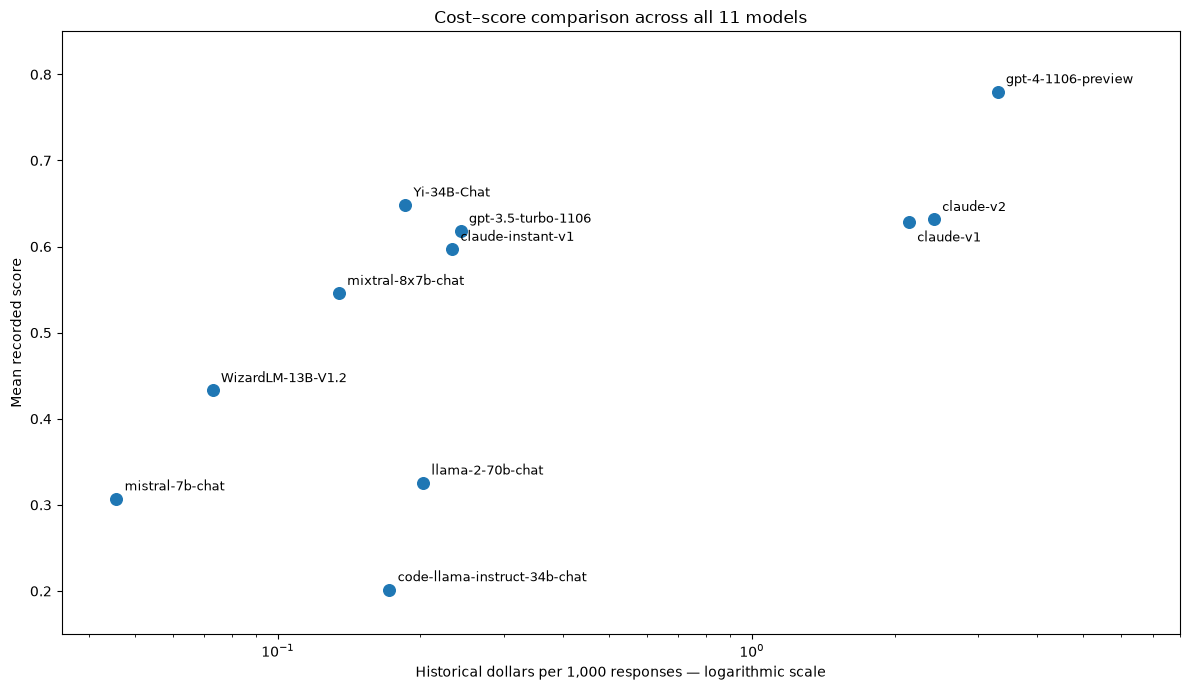

In [81]:
model_summary.plot.scatter(
    x="cost_per_1000_responses",
    y="mean_score",
    figsize=(12, 7),
    s=70
)

plt.xscale("log")

for model, row in model_summary.iterrows():
    label = model.split("/")[-1]
    offset = (6, -14) if model == "claude-v1" else (6, 6)

    plt.annotate(
        label,
        (row["cost_per_1000_responses"], row["mean_score"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Historical dollars per 1,000 responses — logarithmic scale")
plt.ylabel("Mean recorded score")
plt.title("Cost–score comparison across all 11 models")
plt.xlim(0.035, 8)
plt.ylim(0.15, 0.85)

plt.tight_layout()
plt.show()

In [82]:
cost_diagnostics = pd.DataFrame({
    "mean_to_median": costs.mean() / costs.median(),
    "skewness": costs.skew(),
    "coefficient_of_variation": costs.std() / costs.mean()
})

cost_diagnostics.round(3)

,mean_to_median,skewness,coefficient_of_variation
WizardLM/WizardLM-13B-V1.2,1.313,1.112,0.733
claude-instant-v1,1.551,1.470,0.902
claude-v1,1.418,1.826,0.842
claude-v2,1.568,1.374,0.909
gpt-3.5-turbo-1106,1.299,1.376,0.746
gpt-4-1106-preview,1.718,2.266,1.044
meta/code-llama-instruct-34b-chat,1.231,0.978,0.648
meta/llama-2-70b-chat,1.190,1.528,0.657
mistralai/mistral-7b-chat,1.247,6.116,0.823
mistralai/mixtral-8x7b-chat,1.199,1.140,0.656


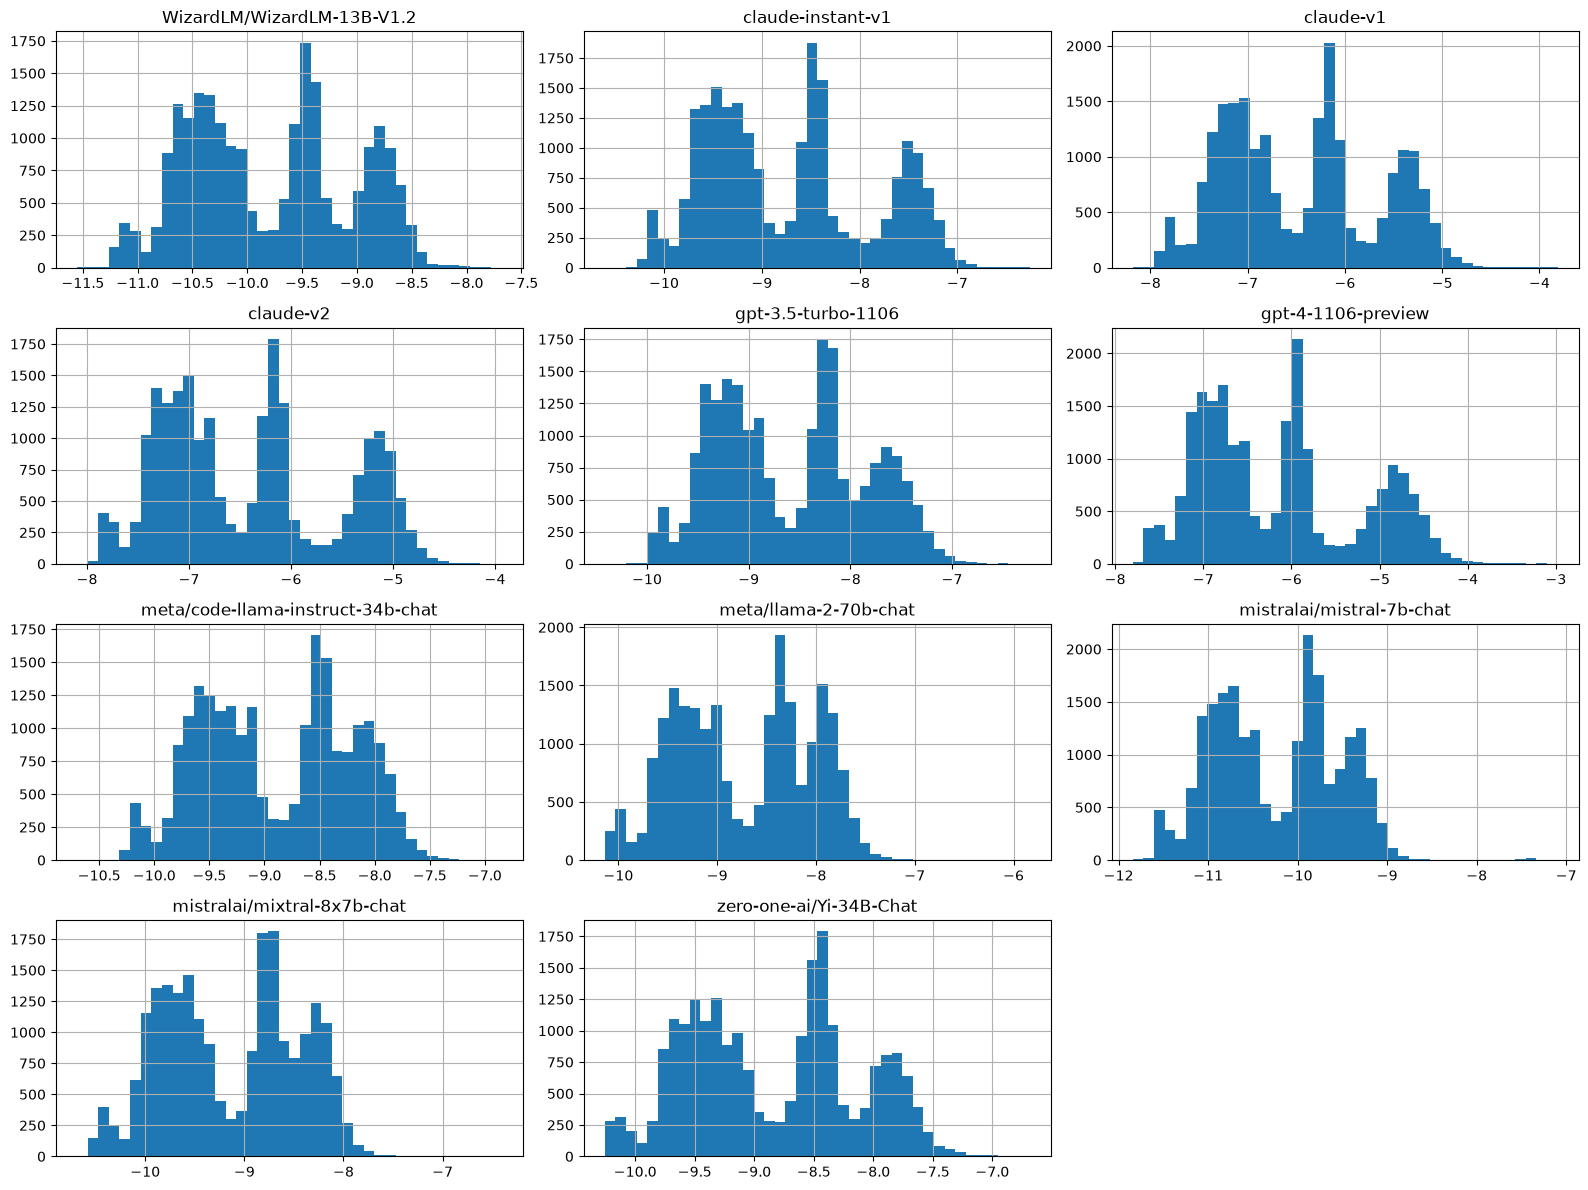

In [83]:
import numpy as np

log_costs = np.log(costs)

log_costs.hist(
    bins=40,
    figsize=(16, 12),
    layout=(4, 3)
)

plt.tight_layout()
plt.show()

In [84]:
# Do the peaks remain after centering within tasks.
# Compute 100 (1- within-task-variation/total-variation) 

task_mean_log_cost = log_costs.groupby(
    df["eval_name"]
).transform("mean")

within_task_log_cost = log_costs - task_mean_log_cost

task_explained_percentage = 100 * (
    1 - within_task_log_cost.var() / log_costs.var()
)

task_explained_percentage.sort_values(ascending=False).round(2)


claude-v2                            89.23
gpt-4-1106-preview                   89.22
claude-instant-v1                    87.81
claude-v1                            86.58
WizardLM/WizardLM-13B-V1.2           84.91
gpt-3.5-turbo-1106                   84.05
meta/llama-2-70b-chat                82.87
mistralai/mixtral-8x7b-chat          82.53
zero-one-ai/Yi-34B-Chat              82.40
meta/code-llama-instruct-34b-chat    82.05
mistralai/mistral-7b-chat            81.31
dtype: float64

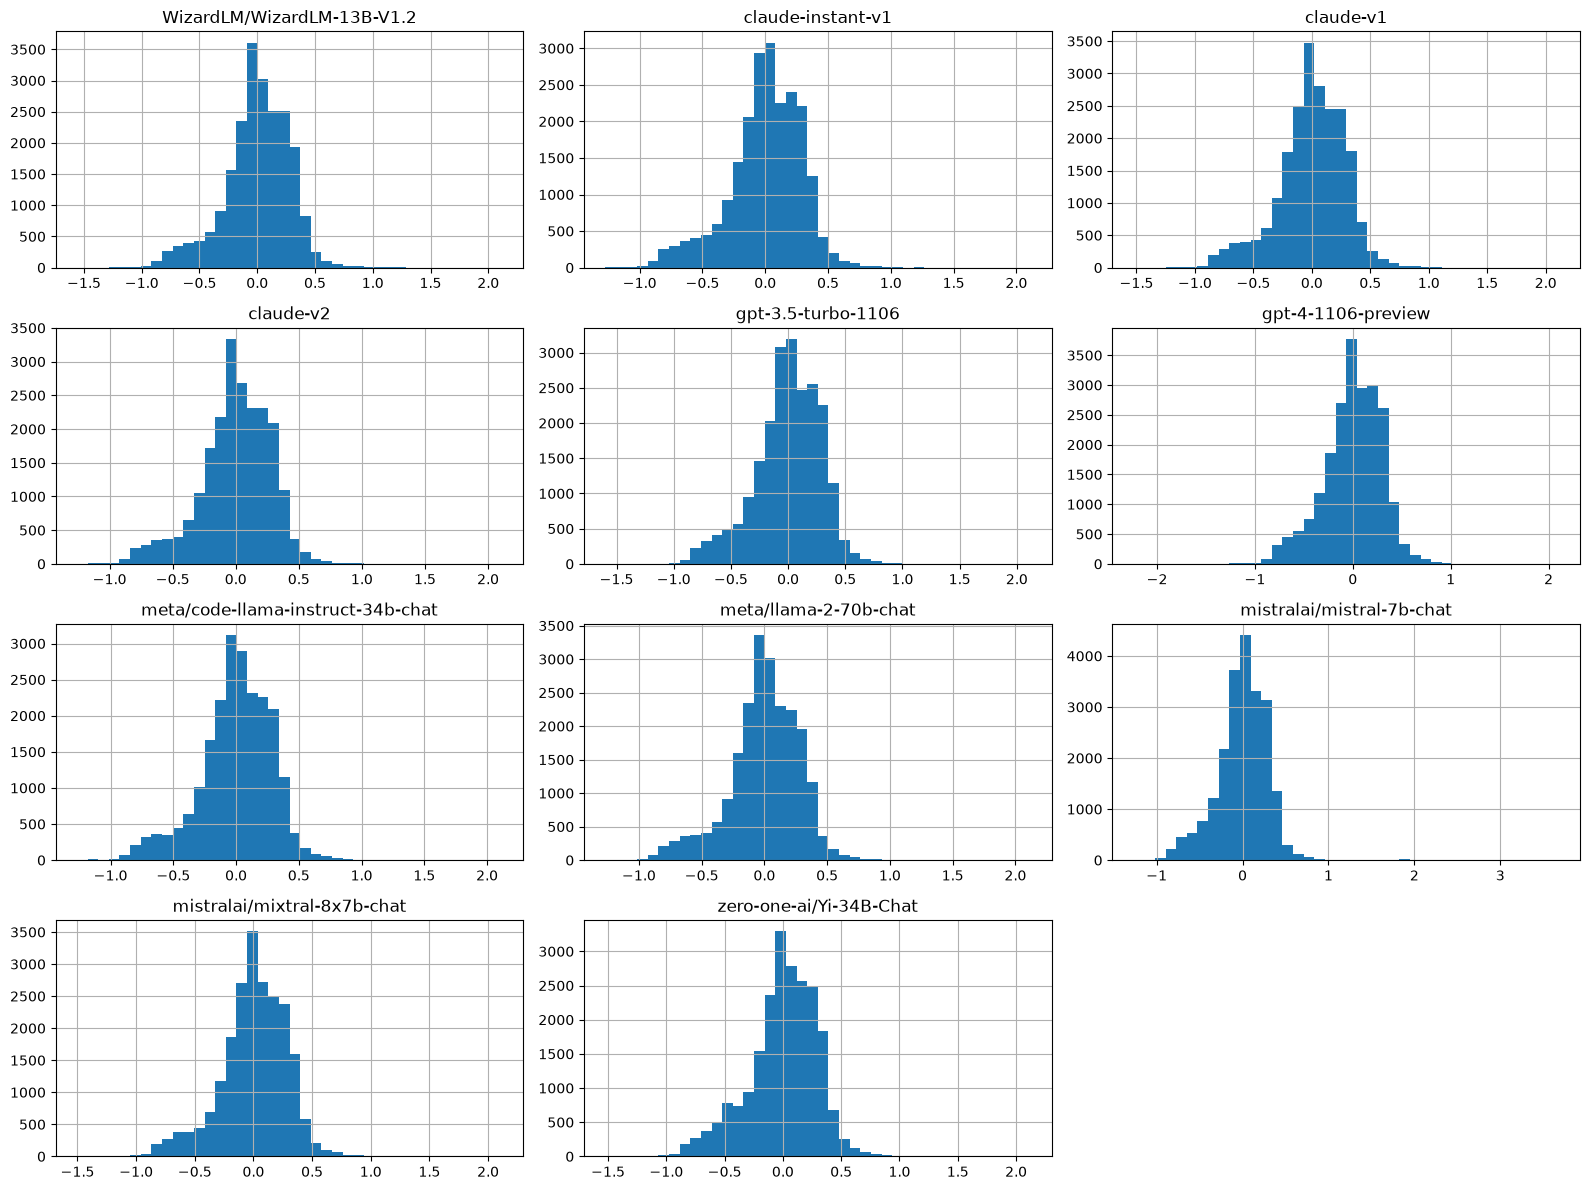

In [85]:
# plot the costs after centering within tasks
within_task_log_cost.hist(
    bins=40,
    figsize=(16, 12),
    layout=(4, 3)
)

plt.tight_layout()
plt.show()
# The separated peaks have largely collapsed.

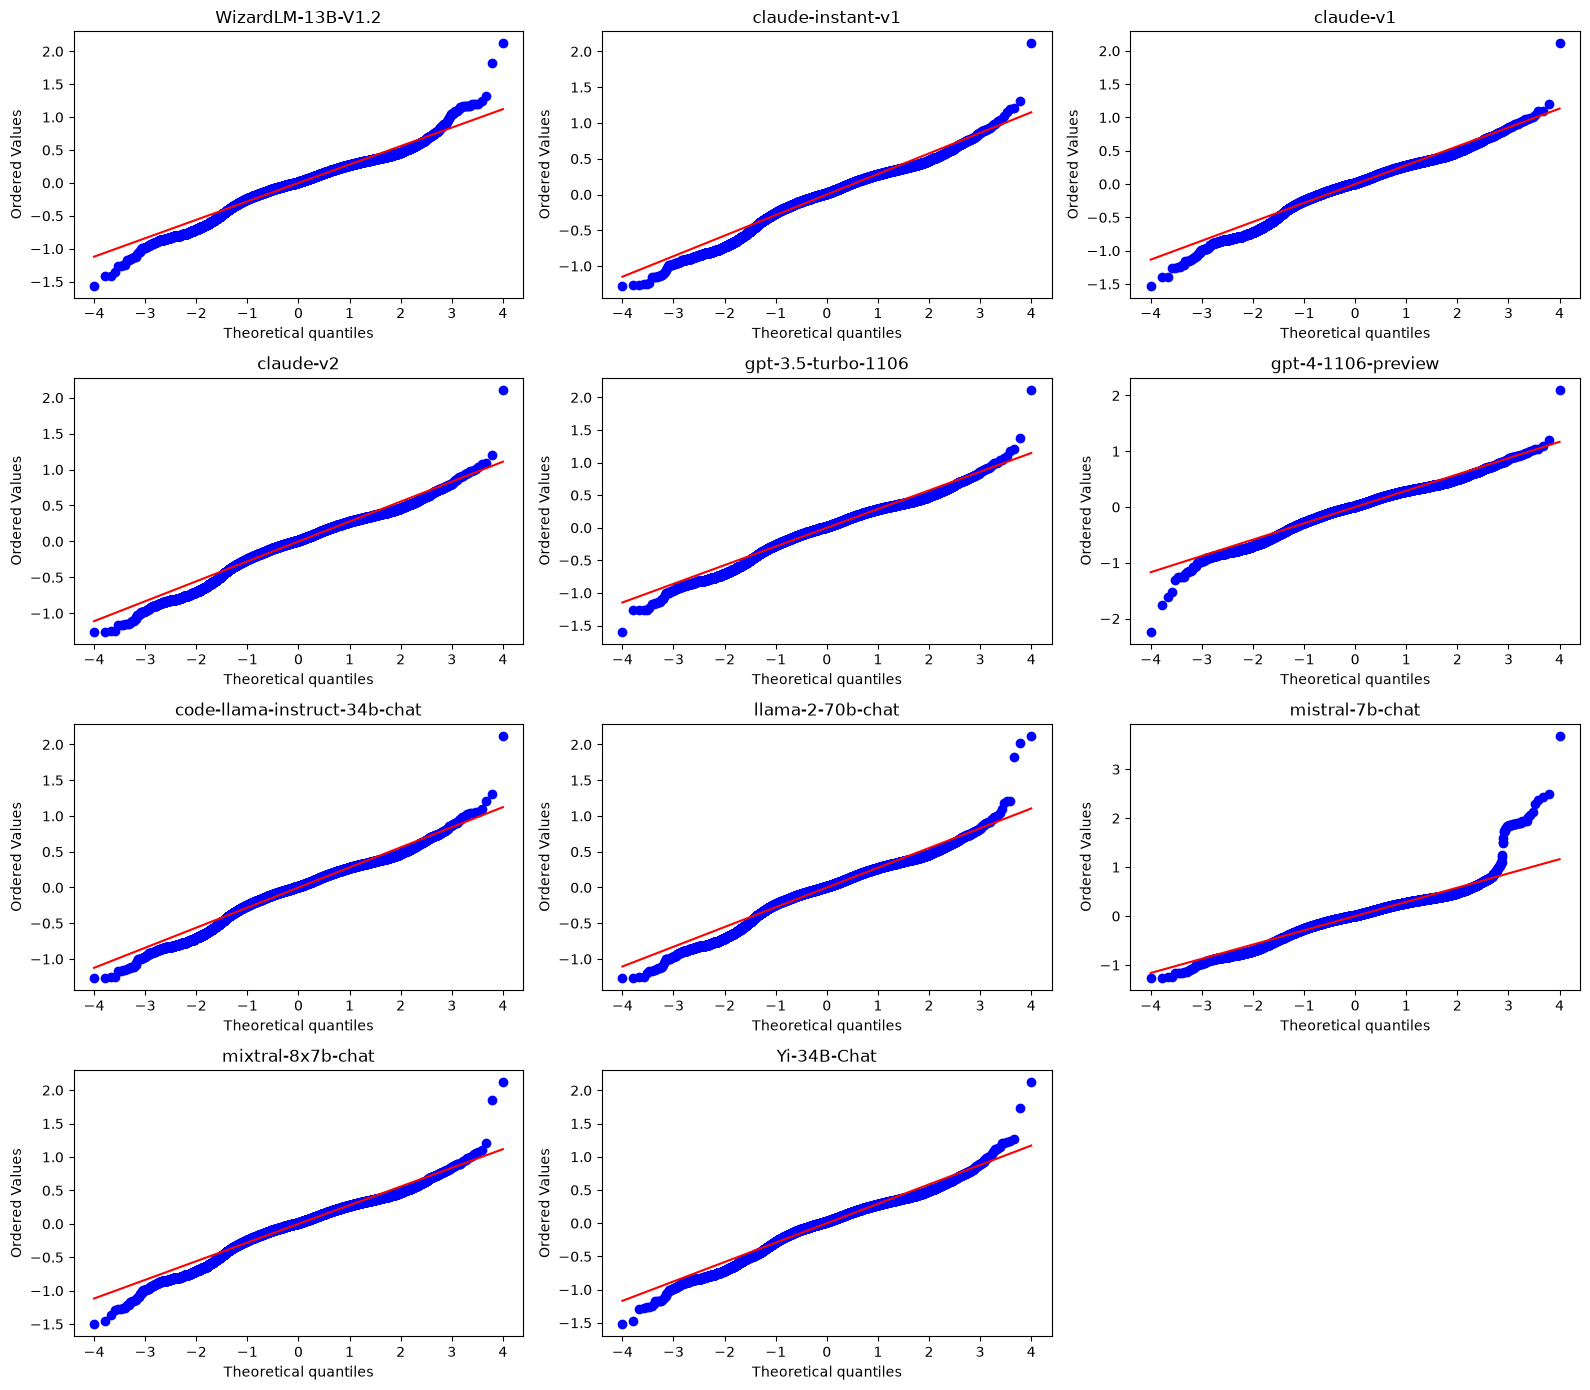

In [86]:
from scipy import stats

fig, axes = plt.subplots(4, 3, figsize=(16, 14))

for ax, model in zip(axes.flat, within_task_log_cost.columns):
    stats.probplot(
        within_task_log_cost[model],
        dist="norm",
        plot=ax
    )

    ax.set_title(model.split("/")[-1])

axes[-1, -1].set_visible(False)

plt.tight_layout()
plt.show()

In [87]:
largest_deviation = within_task_log_cost.max(axis=1)

extreme_rows = largest_deviation.nlargest(10).index

extreme_prompts = df.loc[
    extreme_rows, ["sample_id", "eval_name"]
].copy()

extreme_prompts["model"] = (
    within_task_log_cost.loc[extreme_rows].idxmax(axis=1)
)

extreme_prompts["log_deviation"] = largest_deviation.loc[extreme_rows]

extreme_prompts["cost_ratio"] = np.exp(
    extreme_prompts["log_deviation"]
)

extreme_prompts

,sample_id,eval_name,model,log_deviation,cost_ratio
2182,chinese_ancient_masterpieces_dynasty.dev.2,chinese_ancient_masterpieces_dynasty,mistralai/mistral-7b-chat,3.680530,39.667414
368,accounting_audit.dev.21,accounting_audit,mistralai/mistral-7b-chat,2.491696,12.081753
382,accounting_audit.dev.8,accounting_audit,mistralai/mistral-7b-chat,2.425114,11.303523
2152,chinese-lantern-riddles.dev.3,chinese-lantern-riddles,mistralai/mistral-7b-chat,2.374310,10.743601
2142,chinese-lantern-riddles.dev.11,chinese-lantern-riddles,mistralai/mistral-7b-chat,2.296179,9.936143
22420,mmlu-college-medicine.val.50,mmlu-college-medicine,zero-one-ai/Yi-34B-Chat,2.122923,8.355527
20718,mbpp.dev.134,mbpp,mistralai/mistral-7b-chat,2.073056,7.949081
5360,grade-school-math.dev.2964,grade-school-math,meta/llama-2-70b-chat,2.023919,7.567929
10581,grade-school-math.dev.95,grade-school-math,mistralai/mistral-7b-chat,2.019725,7.536249
6038,grade-school-math.dev.3574,grade-school-math,mistralai/mistral-7b-chat,1.945731,6.998749


In [88]:
#compare all 11 models on the most extreme prompt
row_id = extreme_prompts.index[0]

prompt_comparison = pd.DataFrame({
    "score": scores.loc[row_id],
    "cost_dollars": costs.loc[row_id],
    "relative_cost": np.exp(within_task_log_cost.loc[row_id])
})

prompt_comparison.sort_values(
    "relative_cost", ascending=False
)

,score,cost_dollars,relative_cost
mistralai/mistral-7b-chat,0.0,0.000609,39.667414
claude-v2,1.0,0.002528,2.189600
claude-v1,0.0,0.000440,1.052873
WizardLM/WizardLM-13B-V1.2,0.0,0.000015,0.984386
meta/code-llama-instruct-34b-chat,0.0,0.000037,0.934741
gpt-3.5-turbo-1106,0.0,0.000050,0.926766
gpt-4-1106-preview,0.0,0.000520,0.906367
meta/llama-2-70b-chat,0.0,0.000044,0.886685
claude-instant-v1,0.0,0.000092,0.876365
mistralai/mixtral-8x7b-chat,0.0,0.000035,0.672430


In [89]:
# compare response lengths across all 11 models. A longer generated response is one possible explanation for the unusually high cost
response_columns = scores.columns + "|model_response"

responses = df.loc[row_id, response_columns].copy()

responses.index = scores.columns

response_comparison = prompt_comparison.copy()

response_comparison["stored_response_characters"] = responses.str.len()

response_comparison.sort_values(
    "stored_response_characters", ascending=False
)

,score,cost_dollars,relative_cost,stored_response_characters
mistralai/mistral-7b-chat,0.0,0.000609,39.667414,3859
claude-v2,1.0,0.002528,2.189600,102
claude-instant-v1,0.0,0.000092,0.876365,39
zero-one-ai/Yi-34B-Chat,1.0,0.000058,0.637561,30
meta/llama-2-70b-chat,0.0,0.000044,0.886685,18
mistralai/mixtral-8x7b-chat,0.0,0.000035,0.672430,17
meta/code-llama-instruct-34b-chat,0.0,0.000037,0.934741,16
WizardLM/WizardLM-13B-V1.2,0.0,0.000015,0.984386,6
claude-v1,0.0,0.000440,1.052873,6
gpt-3.5-turbo-1106,0.0,0.000050,0.926766,6


In [90]:
mistral_response = responses["mistralai/mistral-7b-chat"]

print("PROMPT:")
print(df.loc[row_id, "prompt"])

print("\nMISTRAL — FIRST 1500 CHARACTERS:")
print(mistral_response[:1500])

print("\nMISTRAL — LAST 500 CHARACTERS:")
print(mistral_response[-500:])

print("\nYI RESPONSE:")
print(responses["zero-one-ai/Yi-34B-Chat"])


PROMPT:
['下面这本中国古代名著是于哪个朝代编写的？你只需要回答朝代。例如：战国\n---\n《三国志》']

MISTRAL — FIRST 1500 CHARACTERS:
['战国\n\n《论语》\n\n唐代\n\n明代\n\n歌名\n\n《红楼梦》\n\n《水滸传》\n\n《韩国经》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n《水滸传》\n\n

# Prompts

In [91]:
# prompt-length analysis
import ast

prompt_parts = df["prompt"].apply(ast.literal_eval)

prompt_text = prompt_parts.str.join("\n\n").str.strip()

prompt_lengths = prompt_text.str.len()

prompt_lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99])

count    21900.000000
mean       761.329589
std        429.631023
min         26.000000
50%        712.000000
90%       1233.000000
95%       1343.000000
99%       1870.010000
max       4743.000000
Name: prompt, dtype: float64

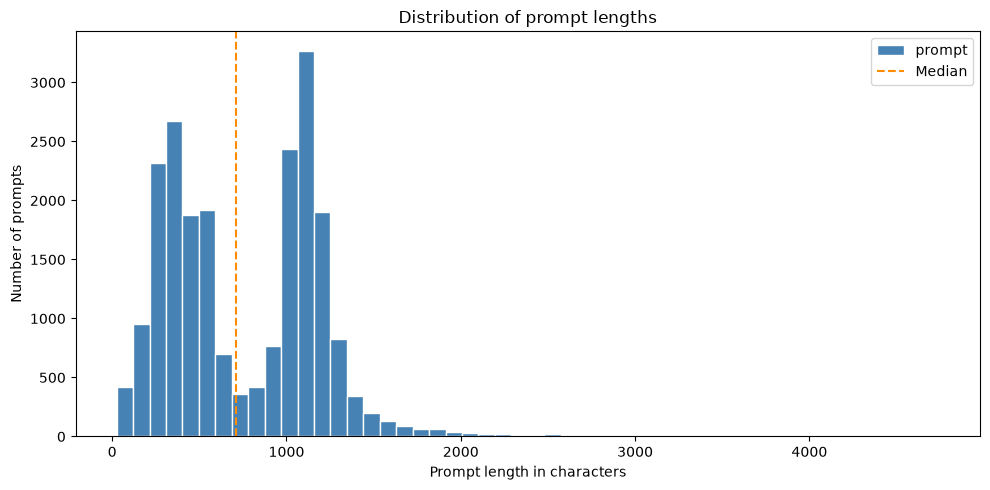

In [92]:
# Plot the prompt-length distribution
prompt_lengths.plot.hist(
    bins=50,
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    prompt_lengths.median(),
    color="darkorange",
    linestyle="--",
    label="Median"
)

plt.xlabel("Prompt length in characters")
plt.ylabel("Number of prompts")
plt.title("Distribution of prompt lengths")
plt.legend()

plt.tight_layout()
plt.show()

In [93]:
# Measure how length relates to score and cost
length_relationships = pd.DataFrame({
    "length_vs_score": scores.corrwith(
        prompt_lengths, method="spearman"
    ),
    "length_vs_cost": costs.corrwith(
        prompt_lengths, method="spearman"
    )
})

length_relationships.round(3)

,length_vs_score,length_vs_cost
WizardLM/WizardLM-13B-V1.2,-0.025,0.874
claude-instant-v1,-0.073,0.849
claude-v1,-0.136,0.846
claude-v2,-0.096,0.835
gpt-3.5-turbo-1106,-0.148,0.866
gpt-4-1106-preview,-0.220,0.830
meta/code-llama-instruct-34b-chat,0.302,0.892
meta/llama-2-70b-chat,0.258,0.867
mistralai/mistral-7b-chat,0.135,0.885
mistralai/mixtral-8x7b-chat,-0.145,0.871


In [94]:
# does the length - cost relationship persist within tasks?
within_task_results = {}

for task in task_counts.head(3).index:
    mask = df["eval_name"].eq(task)

    within_task_results[task] = costs.loc[mask].corrwith(
        prompt_lengths.loc[mask],
        method="spearman"
    )

within_task_length_cost = pd.DataFrame(within_task_results)

within_task_length_cost.round(3)

,hellaswag,grade-school-math,mmlu-professional-law
WizardLM/WizardLM-13B-V1.2,0.96,0.537,0.982
claude-instant-v1,0.96,0.477,0.982
claude-v1,0.96,0.538,0.982
claude-v2,0.96,0.527,0.982
gpt-3.5-turbo-1106,0.96,0.533,0.981
gpt-4-1106-preview,0.96,0.515,0.981
meta/code-llama-instruct-34b-chat,0.96,0.611,0.982
meta/llama-2-70b-chat,0.96,0.632,0.982
mistralai/mistral-7b-chat,0.96,0.476,0.982
mistralai/mixtral-8x7b-chat,0.96,0.503,0.981


In [95]:
import warnings

within_task_score_results = {}

with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")

    for task in task_counts.head(3).index:
        mask = df["eval_name"].eq(task)

        within_task_score_results[task] = scores.loc[mask].corrwith(
            prompt_lengths.loc[mask],
            method="spearman"
        )

# Show each distinct warning without its source-file path.
messages = dict.fromkeys(
    f"{w.category.__name__}: {w.message}" for w in captured
)
for message in messages:
    print(message)

within_task_length_score = pd.DataFrame(within_task_score_results)
within_task_length_score.round(3)

,hellaswag,grade-school-math,mmlu-professional-law
WizardLM/WizardLM-13B-V1.2,-0.106,-0.214,-0.009
claude-instant-v1,-0.046,-0.168,-0.016
claude-v1,-0.038,-0.148,-0.008
claude-v2,0.047,-0.158,0.014
gpt-3.5-turbo-1106,-0.084,-0.185,0.007
gpt-4-1106-preview,0.085,-0.090,-0.004
meta/code-llama-instruct-34b-chat,0.033,-0.205,-0.013
meta/llama-2-70b-chat,0.075,-0.219,NaN
mistralai/mistral-7b-chat,-0.015,-0.153,-0.007
mistralai/mixtral-8x7b-chat,-0.157,-0.139,-0.087


## Comparing models

Summary: Choose the highest-mean model on training data as an exploratory reference. Compare paired scores and costs, then calculate perfect-information savings

In [96]:
# Even though GPT-4 has the highest overall mean score, how often does another model score higher on the same prompt?
reference_model = scores.mean().idxmax()

reference_scores = scores[reference_model]

paired_comparison = pd.DataFrame({
    "higher_score_percent":
        scores.gt(reference_scores, axis=0).mean() * 100,

    "equal_score_percent":
        scores.eq(reference_scores, axis=0).mean() * 100,

    "lower_score_percent":
        scores.lt(reference_scores, axis=0).mean() * 100
})

print("Exploratory reference:", reference_model)

paired_comparison.sort_values(
    "higher_score_percent", ascending=False
).round(2)
# GPT 4 doesn’t score highest on every prompt

Exploratory reference: gpt-4-1106-preview


,higher_score_percent,equal_score_percent,lower_score_percent
claude-instant-v1,8.15,65.72,26.14
claude-v2,8.10,69.87,22.03
claude-v1,7.82,70.16,22.02
gpt-3.5-turbo-1106,7.52,67.21,25.27
zero-one-ai/Yi-34B-Chat,7.44,69.14,23.42
mistralai/mixtral-8x7b-chat,5.99,60.94,33.07
WizardLM/WizardLM-13B-V1.2,5.24,50.55,44.21
mistralai/mistral-7b-chat,4.55,36.89,58.55
meta/llama-2-70b-chat,4.20,42.52,53.28
meta/code-llama-instruct-34b-chat,3.11,30.45,66.45


In [97]:
# measure the magnitude of gains and losses by choosing a different model than GPT 4
score_differences = scores.sub(reference_scores, axis=0)

gain_and_loss = pd.DataFrame({
    "mean_gain": score_differences.clip(lower=0).mean(),

    "mean_loss": (-score_differences).clip(lower=0).mean(),

    "net_difference": score_differences.mean()
})

gain_and_loss.sort_values(
    "mean_gain", ascending=False
).round(4)

,mean_gain,mean_loss,net_difference
zero-one-ai/Yi-34B-Chat,0.0534,0.1849,-0.1314
gpt-3.5-turbo-1106,0.0524,0.2142,-0.1619
claude-v2,0.0487,0.1970,-0.1483
claude-instant-v1,0.0487,0.2316,-0.1830
claude-v1,0.0444,0.1959,-0.1514
mistralai/mixtral-8x7b-chat,0.0403,0.2745,-0.2342
WizardLM/WizardLM-13B-V1.2,0.0356,0.3827,-0.3471
mistralai/mistral-7b-chat,0.0332,0.5060,-0.4728
meta/llama-2-70b-chat,0.0231,0.4775,-0.4544
meta/code-llama-instruct-34b-chat,0.0165,0.5948,-0.5783


In [98]:
# how often is another model cheaper without lowering the recorded score?
reference_costs = costs[reference_model]

no_lower_score = scores.ge(reference_scores, axis=0)

lower_cost = costs.lt(reference_costs, axis=0)

cheaper_without_score_loss = no_lower_score & lower_cost

(
    cheaper_without_score_loss.mean() * 100
).sort_values(ascending=False).round(2)


claude-v1                            77.92
claude-v2                            76.61
zero-one-ai/Yi-34B-Chat              76.58
gpt-3.5-turbo-1106                   74.73
claude-instant-v1                    73.86
mistralai/mixtral-8x7b-chat          66.93
WizardLM/WizardLM-13B-V1.2           55.79
meta/llama-2-70b-chat                46.72
mistralai/mistral-7b-chat            41.44
meta/code-llama-instruct-34b-chat    33.55
gpt-4-1106-preview                    0.00
dtype: float64

In [99]:
# If we knew every outcome beforehand, what would be the cheapest model on each prompt whose score was at least GPT-4’s?
eligible_costs = costs.where(no_lower_score)

hindsight_cost = eligible_costs.min(axis=1)

savings_fraction = (
    1 - hindsight_cost.mean() / reference_costs.mean()
)

print(
    "GPT-4 dollars per 1,000 responses:",
    reference_costs.mean() * 1000
)

print(
    "Hindsight dollars per 1,000 responses:",
    hindsight_cost.mean() * 1000
)

print("Aggregate cost savings (%):", savings_fraction * 100)


GPT-4 dollars per 1,000 responses: 3.298159360730594
Hindsight dollars per 1,000 responses: 0.20734001022831053
Aggregate cost savings (%): 93.71346294854649


In [100]:
# where do those savings come from?
hindsight_model = eligible_costs.idxmin(axis=1)

routing_counts = hindsight_model.value_counts().reindex(
    scores.columns, fill_value=0
)

spending_by_model = hindsight_cost.groupby(
    hindsight_model
).sum().reindex(scores.columns, fill_value=0)

routing_summary = pd.DataFrame({
    "prompt_count": routing_counts,
    "prompt_percent": 100 * routing_counts / len(df),
    "spending_percent": 100 * spending_by_model / hindsight_cost.sum()
})

routing_summary.sort_values(
    "prompt_percent", ascending=False
).round(2)

,prompt_count,prompt_percent,spending_percent
mistralai/mistral-7b-chat,9042,41.29,8.53
WizardLM/WizardLM-13B-V1.2,4767,21.77,7.40
mistralai/mixtral-8x7b-chat,3279,14.97,9.22
zero-one-ai/Yi-34B-Chat,2524,11.53,10.97
claude-instant-v1,620,2.83,3.36
gpt-4-1106-preview,464,2.12,35.83
gpt-3.5-turbo-1106,437,2.00,2.93
meta/llama-2-70b-chat,291,1.33,1.93
meta/code-llama-instruct-34b-chat,224,1.02,1.47
claude-v1,140,0.64,9.87


In [101]:
# are the savings concentrated on prompts where GPT-4 scored zero?
benchmark_details = pd.DataFrame({
    "reference_score": reference_scores,
    "reference_cost": reference_costs,
    "hindsight_cost": hindsight_cost
})

by_reference_score = benchmark_details.groupby(
    "reference_score"
).agg(
    prompt_count=("reference_cost", "size"),
    reference_mean_cost=("reference_cost", "mean"),
    hindsight_mean_cost=("hindsight_cost", "mean")
)

by_reference_score["savings_percent"] = 100 * (
    1
    - by_reference_score["hindsight_mean_cost"]
    / by_reference_score["reference_mean_cost"]
)

by_reference_score.round(6)

,prompt_count,reference_mean_cost,hindsight_mean_cost,savings_percent
reference_score,,,,
0.00,3220,0.002306,0.000034,98.527777
0.10,4,0.014580,0.000073,99.496914
0.25,223,0.009246,0.000092,99.006703
0.30,2,0.015505,0.010283,33.682038
0.50,1285,0.008320,0.000377,95.470373
0.75,3131,0.008372,0.000542,93.528281
0.80,2,0.032215,0.015457,52.020487
0.90,4,0.020470,0.013750,32.829038
1.00,14029,0.001825,0.000151,91.706091


In [102]:
# which tasks account for the spending that remains?

task_benchmark = benchmark_details.assign(
    task=df["eval_name"]
).groupby("task").agg(
    prompt_count=("reference_cost", "size"),
    reference_spend=("reference_cost", "sum"),
    hindsight_spend=("hindsight_cost", "sum")
)

task_benchmark["savings_percent"] = 100 * (
    1
    - task_benchmark["hindsight_spend"]
    / task_benchmark["reference_spend"]
)

task_benchmark["hindsight_spend_share"] = 100 * (
    task_benchmark["hindsight_spend"]
    / task_benchmark["hindsight_spend"].sum()
)

task_benchmark.sort_values(
    "hindsight_spend", ascending=False
).head(10).round(4)

,prompt_count,reference_spend,hindsight_spend,savings_percent,hindsight_spend_share
task,,,,,
grade-school-math,4492,38.4757,2.2136,94.2467,48.7503
hellaswag,5997,12.9310,0.8608,93.3435,18.9563
mmlu-professional-law,925,2.6596,0.1639,93.8384,3.6090
mmlu-moral-scenarios,567,0.8115,0.1537,81.0572,3.3853
mtbench-reference,11,0.2581,0.1319,48.8979,2.9050
mbpp,260,2.4446,0.1221,95.0051,2.6891
mtbench,27,0.7154,0.0782,89.0630,1.7232
chinese_zodiac,239,0.2753,0.0567,79.3934,1.2494
Chinese_character_riddles,62,0.6274,0.0467,92.5505,1.0293


In [103]:
# rank tasks by cost per response instead of total spending
task_benchmark["reference_cost_per_1000"] = (
    1000
    * task_benchmark["reference_spend"]
    / task_benchmark["prompt_count"]
)

task_benchmark["hindsight_cost_per_1000"] = (
    1000
    * task_benchmark["hindsight_spend"]
    / task_benchmark["prompt_count"]
)

task_benchmark.sort_values(
    "hindsight_cost_per_1000", ascending=False
)[[
    "prompt_count",
    "reference_cost_per_1000",
    "hindsight_cost_per_1000",
    "savings_percent"
]].head(10).round(3)

,prompt_count,reference_cost_per_1000,hindsight_cost_per_1000,savings_percent
task,,,,
mtbench-reference,11,23.466,11.992,48.898
mtbench,27,26.497,2.898,89.063
mtbench-math,10,14.700,2.636,82.071
chinese_idioms,13,6.194,1.060,82.888
Chinese_character_riddles,62,10.119,0.754,92.551
chinese_modern_poem_identification,14,1.463,0.678,53.667
grade-school-math,4492,8.565,0.493,94.247
mbpp,260,9.402,0.470,95.005
chinese_song_ci,10,1.466,0.330,77.509


In [104]:
# check how task weighting affects the overall savings. What if we instead give every task equal weight?
weighting_comparison = pd.DataFrame({
    "reference_cost_per_1000": [
        reference_costs.mean() * 1000,
        task_benchmark["reference_cost_per_1000"].mean()
    ],
    "hindsight_cost_per_1000": [
        hindsight_cost.mean() * 1000,
        task_benchmark["hindsight_cost_per_1000"].mean()
    ]
}, index=[
    "Equal weight per prompt",
    "Equal weight per task"
])

weighting_comparison["savings_percent"] = 100 * (
    1
    - weighting_comparison["hindsight_cost_per_1000"]
    / weighting_comparison["reference_cost_per_1000"]
)

weighting_comparison.round(3)

,reference_cost_per_1000,hindsight_cost_per_1000,savings_percent
Equal weight per prompt,3.298,0.207,93.713
Equal weight per task,2.758,0.333,87.938


## Some other checks

In [105]:
# check repeated prompts
duplicate_check = pd.Series({
    "Duplicate IDs beyond the first occurrence":
        df["sample_id"].duplicated().sum(),

    "Duplicate prompt texts beyond the first occurrence":
        prompt_text.duplicated().sum(),

    "Rows belonging to repeated-text groups":
        prompt_text.duplicated(keep=False).sum()
})

duplicate_check

Duplicate IDs beyond the first occurrence              0
Duplicate prompt texts beyond the first occurrence    12
Rows belonging to repeated-text groups                24
dtype: int64

In [106]:
# those paired records have identical scores and costs?

duplicate_mask = prompt_text.duplicated(keep=False)

duplicate_groups = prompt_text.loc[duplicate_mask]

score_variation = (
    scores.loc[duplicate_mask]
    .groupby(duplicate_groups)
    .nunique()
)

cost_variation = (
    costs.loc[duplicate_mask]
    .groupby(duplicate_groups)
    .nunique()
)

print(
    "Groups with at least one differing model score:",
    score_variation.gt(1).any(axis=1).sum()
)

print(
    "Groups with at least one differing model cost:",
    cost_variation.gt(1).any(axis=1).sum()
)

Groups with at least one differing model score: 4
Groups with at least one differing model cost: 9


In [107]:
# check the overlap and task labels
duplicate_audit = pd.DataFrame({
    "score_differs": score_variation.gt(1).any(axis=1),

    "cost_differs": cost_variation.gt(1).any(axis=1),

    "task_count": (
        df.loc[duplicate_mask]
        .groupby(duplicate_groups)["eval_name"]
        .nunique()
    )
})

duplicate_audit.groupby(
    ["score_differs", "cost_differs", "task_count"]
).size()

score_differs  cost_differs  task_count
False          False         1             3
               True          1             5
True           True          1             4
dtype: int64

In [108]:
# Verify that this EDA still contains exactly the saved training rows.
assert df["sample_id"].is_unique
assert set(df["sample_id"]) == set(train_ids)

print("Rows in saved training partition:", len(train_ids))
print("Rows used in this EDA:", len(df))
print("Training IDs match exactly. Existing splits were not changed.")

Rows in saved training partition: 21900
Rows used in this EDA: 21900
Training IDs match exactly. Existing splits were not changed.
